# EDA final · cancelación de reservas de hotel

**Máster en IA, Cloud Computing y DevOps** · Machine Learning y Deep Learning · Práctica final

Si `eda_inicial.ipynb` es la cocina, este es el escaparate: aquí **no se explora**, se
*presenta*. Solo entra lo que sobrevivió a la exploración y **cambió una decisión** del
proyecto. Cada sección termina en una frase que empieza por «Decisión:».

Es el notebook que se abre en la defensa, así que tiene que ejecutarse de arriba abajo
sin errores y **con las salidas guardadas**: un notebook sin outputs obliga al profesor a
ejecutarlo para ver tu trabajo.

> La tabla del final es literalmente la del apartado 3 del README. Se rellena una vez, aquí.

In [1]:
import sys, pathlib

# Subir hasta la raiz del proyecto (la carpeta que contiene src/), la abras desde donde la abras.
raiz = next(d for d in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (d / "src").is_dir())
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config

pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv(config.DATA_RAW, na_values=["NULL", "null", "", " "])
print(f"{df.shape[0]:,} filas x {df.shape[1]} columnas".replace(",", "."))
df.head()

119.390 filas x 32 columnas


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 1. El objetivo y su desbalanceo

El número que hunde a `accuracy` como métrica principal: un modelo que dijera siempre
«no cancela» ya acierta el 62,96 % sin haber aprendido nada.

Porcentajes del dataset original:
is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64


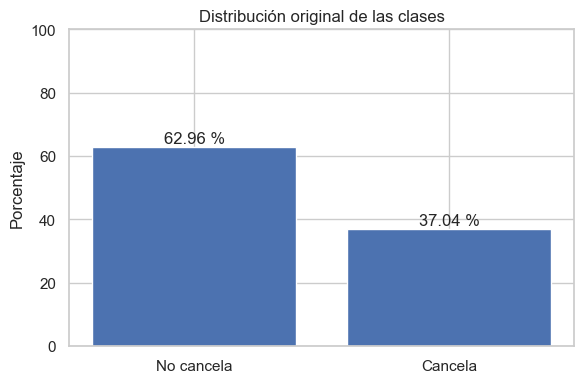

In [3]:
reparto = (
    df[config.OBJETIVO]
    .value_counts(normalize=True)
    .sort_index()
)

print("Porcentajes del dataset original:")
print(reparto.mul(100).round(2))

fig, ax = plt.subplots(figsize=(6, 4))
porcentajes = reparto.mul(100)

ax.bar(["No cancela", "Cancela"], porcentajes.values)

for posicion, porcentaje in enumerate(porcentajes.values):
    ax.text(
        posicion,
        porcentaje + 1,
        f"{porcentaje:.2f} %",
        ha="center",
    )

ax.set_ylabel("Porcentaje")
ax.set_title("Distribución original de las clases")
ax.set_ylim(0, 100)
fig.tight_layout()
plt.show()

**Decisión:** utilizar F1 de la clase positiva —cancelación— como
métrica principal, y conservar accuracy como secundaria.

En los datos originales, predecir siempre «no cancela» ya obtiene
aproximadamente un 62,96 % de accuracy. Por tanto, accuracy por sí sola
no demuestra que el modelo detecte cancelaciones.

## 2. La fuga: la columna que es la respuesta con otro nombre

`reservation_status` determina `is_canceled` al 100 %: `Check-Out` → 0, `Canceled` y
`No-Show` → 1. Es la etiqueta escrita de otra manera.

In [4]:
tabla = pd.crosstab(df["reservation_status"], df[config.OBJETIVO])
display(tabla)

# La prueba: ninguna fila de la tabla tiene las dos columnas a la vez distintas de cero.
print("determina el objetivo al 100 %?", bool(((tabla > 0).sum(axis=1) == 1).all()))

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


determina el objetivo al 100 %? True


**Decisión:** excluir las cuatro columnas de `config.FUGAS`: `reservation_status` y
`reservation_status_date` (revelan el desenlace al 100 %, como muestra la tabla) y
`required_car_parking_spaces` y `assigned_room_type` (se rellenan a la llegada del
cliente, después del momento de predecir). 32 − `is_canceled` − 4 fugas = **27 predictoras**.

## 3. Nulos, duplicados e imposibles

Cuánto se pierde en cada paso de la limpieza. Estos números van al README: «se
eliminaron N filas» sin decir cuántas ni por qué no vale.

In [5]:
from src import data_loader

# 1. Porcentaje de valores ausentes
nulos = df.isna().mean().mul(100).sort_values(ascending=False)

display(nulos.to_frame("porcentaje_nulos"))

# 2. Quitar fugas antes de identificar duplicados
sin_fugas = df.drop(columns=config.FUGAS)

# 3. Aplicar la política de duplicados del proyecto
sin_duplicados = (
    sin_fugas.drop_duplicates()
    if config.ELIMINAR_DUPLICADOS
    else sin_fugas.copy()
)

# 4. Identificar registros imposibles después de deduplicar
adr_negativo = sin_duplicados["adr"] < 0

sin_huespedes = (
    sin_duplicados[["adults", "children", "babies"]]
    .fillna(0)
    .sum(axis=1) == 0
)

cantidad_adr = int(adr_negativo.sum())

# Evitar contar dos veces una fila con ambos problemas
cantidad_sin_huespedes = int(
    (sin_huespedes & ~adr_negativo).sum()
)

# 5. Obtener el resultado de la función real del proyecto
limpio = data_loader.limpiar(df)

resumen = pd.DataFrame([
    ("Original", 0, len(df)),
    ("Excluir fugas: solo columnas", 0, len(sin_fugas)),
    (
        "Eliminar duplicados",
        len(sin_fugas) - len(sin_duplicados),
        len(sin_duplicados),
    ),
    (
        "Eliminar ADR negativo",
        cantidad_adr,
        len(sin_duplicados) - cantidad_adr,
    ),
    (
        "Eliminar reservas sin huéspedes",
        cantidad_sin_huespedes,
        len(limpio),
    ),
], columns=["Etapa", "Filas eliminadas", "Filas restantes"])

display(resumen)

print("Porcentajes después de limpiar:")
print(
    limpio[config.OBJETIVO]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

,porcentaje_nulos
company,94.306893
agent,13.686238
country,0.408744
children,0.003350
reserved_room_type,0.000000
assigned_room_type,0.000000
booking_changes,0.000000
deposit_type,0.000000
hotel,0.000000
previous_cancellations,0.000000


      [limpieza] fugas: -4 columnas (reservation_status, reservation_status_date, required_car_parking_spaces, assigned_room_type)
      [limpieza] duplicados exactos: -33.413 filas
      [limpieza] adr negativo: -1 filas
      [limpieza] 0 huéspedes: -165 filas
      [limpieza] total: 119.390 -> 85.811 filas


,Etapa,Filas eliminadas,Filas restantes
0,Original,0,119390
1,Excluir fugas: solo columnas,0,119390
2,Eliminar duplicados,33413,85977
3,Eliminar ADR negativo,1,85976
4,Eliminar reservas sin huéspedes,165,85811


Porcentajes después de limpiar:
is_canceled
0    72.36
1    27.64
Name: proportion, dtype: float64


**Decisión:** eliminar las fugas, después los duplicados y finalmente
los registros imposibles, antes de dividir los datos en train y test.

La deduplicación reduce el riesgo de que una copia exacta aparezca
en ambos conjuntos. Como no existe un identificador de reserva,
también podría retirar reservas legítimas similares: se reconoce
como limitación.

Se excluyen las reservas con ADR negativo o sin huéspedes.
Los valores ausentes se tratan mediante el preprocesamiento del Pipeline,
sin eliminar de forma general todas las filas con nulos.

## 4. Cardinalidad: qué pasa si haces one-hot de todo

`country`, `agent` y `company` tienen numerosas categorías.
El one-hot directo puede ampliar mucho las 27 variables predictoras.
A continuación se mide esa ampliación sobre los datos limpios.

In [6]:
X_eda = limpio.drop(columns=config.OBJETIVO)

# Incluir agent y company aunque sus IDs tengan tipo numérico
categoricas = list(dict.fromkeys(
    list(X_eda.select_dtypes(include="object").columns)
    + config.ALTA_CARDINALIDAD
))

cardinalidad = (
    X_eda[categoricas]
    .nunique()
    .sort_values(ascending=False)
)

display(cardinalidad.to_frame("categorias_distintas"))

cantidad_onehot = pd.get_dummies(
    X_eda,
    columns=categoricas,
).shape[1]

print("Variables predictoras originales:", X_eda.shape[1])
print("Columnas con one-hot directo en este análisis:", cantidad_onehot)

,categorias_distintas
company,348
agent,333
country,177
arrival_date_month,12
reserved_room_type,9
market_segment,8
meal,5
distribution_channel,5
customer_type,4
deposit_type,3


Variables predictoras originales: 27
Columnas con one-hot directo en este análisis: 922


**Decisión:** agrupar las categorías infrecuentes de `country`, `agent`
y `company`, conservando las diez categorías principales y un grupo
para las restantes.

El agrupamiento se aprende dentro del Pipeline en cada fold,
junto con la imputación y el resto del preprocesamiento.
Así se evita aprender las categorías frecuentes a partir del conjunto
de validación o test.

## 5. Dónde está la señal: tasa de cancelación por grupo

Lo que de verdad se le enseña al profesor. Una variable es útil si la tasa de
cancelación **cambia mucho** entre sus categorías; si todas rondan la media (27,6 % tras limpiar), no aporta.

In [7]:
def tasa_por(columna, minimo=500):
    """Resume categorías con al menos minimo reservas."""
    grupos = limpio.groupby(columna)[config.OBJETIVO].agg(
        tasa_cancelacion="mean",
        reservas="size",
    )

    grupos = grupos[grupos["reservas"] >= minimo]
    grupos["porcentaje_cancelacion"] = (
        grupos["tasa_cancelacion"] * 100
    )

    return grupos.sort_values(
        "porcentaje_cancelacion",
        ascending=False,
    )


for columna in [
    "deposit_type",
    "market_segment",
    "customer_type",
    "hotel",
    "country",
]:
    print(f"\nVariable: {columna}")
    display(tasa_por(columna).head(15))


Variable: deposit_type


,tasa_cancelacion,reservas,porcentaje_cancelacion
deposit_type,,,
Non Refund,0.948566,1011,94.856578
No Deposit,0.268349,84707,26.834854



Variable: market_segment


,tasa_cancelacion,reservas,porcentaje_cancelacion
market_segment,,,
Online TA,0.353455,51271,35.345517
Groups,0.282377,4409,28.237696
Offline TA/TO,0.148832,13438,14.883167
Direct,0.147416,11688,14.741615
Complementary,0.124633,682,12.463343
Corporate,0.120635,4095,12.063492



Variable: customer_type


,tasa_cancelacion,reservas,porcentaje_cancelacion
customer_type,,,
Transient,0.301236,71439,30.123602
Contract,0.163730,3121,16.372957
Transient-Party,0.152324,10714,15.232406
Group,0.098696,537,9.869646



Variable: hotel


,tasa_cancelacion,reservas,porcentaje_cancelacion
hotel,,,
City Hotel,0.302082,52413,30.208154
Resort Hotel,0.236032,33398,23.603210



Variable: country


,tasa_cancelacion,reservas,porcentaje_cancelacion
country,,,
CHN,0.484472,805,48.447205
RUS,0.398551,552,39.855072
BRA,0.365336,1979,36.533603
PRT,0.358649,26742,35.864932
ITA,0.353274,3009,35.327351
NOR,0.281496,508,28.149606
ESP,0.259675,7132,25.967471
CHE,0.245524,1564,24.552430
USA,0.245283,1855,24.528302


**Decisión:** conservar estas variables como candidatas predictoras,
porque permiten examinar diferencias de cancelación entre grupos.

Las tablas muestran asociaciones, no relaciones causales. La utilidad
predictiva de las variables se evalúa mediante el protocolo de validación
del proyecto. Se muestran categorías con al menos 500 reservas para
evitar destacar porcentajes basados en muy pocos casos.

Lo que muestran las tablas: `Non Refund` cancela un 94,9 % frente al 26,8 % de
`No Deposit`; `Online TA` un 35,3 % frente al 12,1 % de `Corporate`; y el City Hotel un
30,2 % frente al 23,6 % del Resort. Hay señal real en depósito, canal y hotel.

## 6. Las numéricas que más separan

`lead_time` es la candidata clara: cuanto antes reservas, más margen hay para arrepentirse.

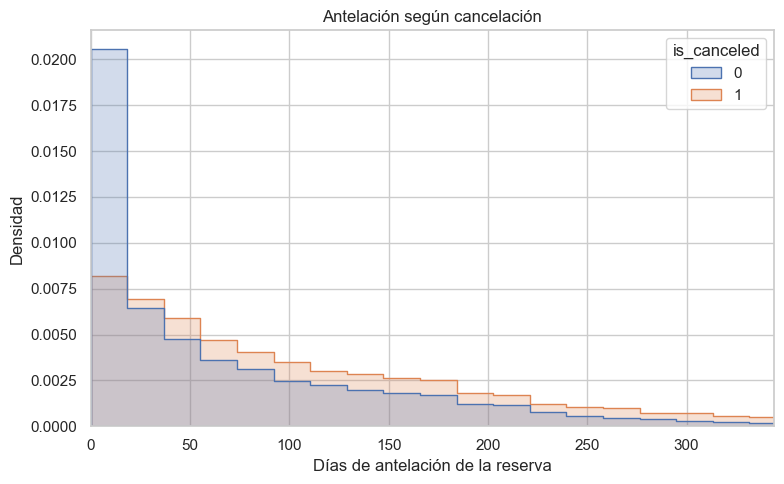

,mediana_lead_time
is_canceled,
0,37.0
1,79.0


In [8]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    data=limpio,
    x="lead_time",
    hue=config.OBJETIVO,
    bins=40,
    element="step",
    stat="density",
    common_norm=False,
    ax=ax,
)

ax.set_xlim(0, limpio["lead_time"].quantile(0.99))
ax.set_xlabel("Días de antelación de la reserva")
ax.set_ylabel("Densidad")
ax.set_title("Antelación según cancelación")
fig.tight_layout()
plt.show()

medianas = limpio.groupby(config.OBJETIVO)["lead_time"].median()
display(medianas.to_frame("mediana_lead_time"))

**Decisión:** conservar `lead_time` como variable candidata y aplicar
a las numéricas imputación por mediana y escalado dentro del Pipeline.

La visualización se limita al percentil 99 para facilitar su lectura;
los valores extremos siguen presentes en los datos.
Las diferencias entre clases describen una asociación, no una causa.

Medianas: **37 días** en las reservas que no cancelan frente a **79 días** en las que
cancelan. Las reservas hechas con mucha antelación cancelan bastante más.

## 7. La tabla que va al README

El apartado 3 del README se puntúa por lo que **cambió**, no por el número de gráficos.
Un hallazgo sin decisión al lado no suma.

In [9]:
mas_nulos = nulos.idxmax()

hallazgos = pd.DataFrame([
    ("Desbalance de clases",
     f"No cancela tras limpiar: {limpio[config.OBJETIVO].eq(0).mean():.2%}",
     "F1 como métrica principal; accuracy solo secundaria"),
    ("Fugas",
     f"{len(config.FUGAS)} columnas: reservation_status determina el objetivo al 100 %",
     "Excluirlas antes de entrenar → 27 predictoras"),
    ("Duplicados exactos",
     f"{len(sin_fugas) - len(sin_duplicados):,} filas eliminadas".replace(",", "."),
     "Deduplicar antes de particionar; reconocer la limitación"),
    ("Valores ausentes",
     f"{mas_nulos}: {nulos[mas_nulos]:.2f} % de nulos en el original",
     "Imputar dentro del Pipeline"),
    ("Alta cardinalidad",
     f"{X_eda['country'].nunique()} países, {X_eda['agent'].nunique()} agentes, "
     f"{X_eda['company'].nunique()} empresas",
     "Top 10 + «otros» dentro de cada fold"),
    ("Depósito no reembolsable",
     f"Non Refund cancela {tasa_por('deposit_type').loc['Non Refund', 'porcentaje_cancelacion']:.1f} %",
     "Conservar deposit_type (asociación, no causa)"),
    ("Antelación de la reserva",
     f"Mediana lead_time: no cancela={medianas.loc[0]:.0f} días; cancela={medianas.loc[1]:.0f} días",
     "Conservar lead_time; mediana + escalado en el Pipeline"),
], columns=["Hallazgo", "Evidencia", "Decisión"])

display(hallazgos)
print(hallazgos.to_markdown(index=False))

,Hallazgo,Evidencia,Decisión
0,Desbalance de clases,No cancela tras limpiar: 72.36%,F1 como métrica principal; accuracy solo secun...
1,Fugas,4 columnas: reservation_status determina el ob...,Excluirlas antes de entrenar → 27 predictoras
2,Duplicados exactos,33.413 filas eliminadas,Deduplicar antes de particionar; reconocer la ...
3,Valores ausentes,company: 94.31 % de nulos en el original,Imputar dentro del Pipeline
4,Alta cardinalidad,"177 países, 333 agentes, 348 empresas",Top 10 + «otros» dentro de cada fold
5,Depósito no reembolsable,Non Refund cancela 94.9 %,"Conservar deposit_type (asociación, no causa)"
6,Antelación de la reserva,Mediana lead_time: no cancela=37 días; cancela...,Conservar lead_time; mediana + escalado en el ...


| Hallazgo                 | Evidencia                                                     | Decisión                                                 |
|:-------------------------|:--------------------------------------------------------------|:---------------------------------------------------------|
| Desbalance de clases     | No cancela tras limpiar: 72.36%                               | F1 como métrica principal; accuracy solo secundaria      |
| Fugas                    | 4 columnas: reservation_status determina el objetivo al 100 % | Excluirlas antes de entrenar → 27 predictoras            |
| Duplicados exactos       | 33.413 filas eliminadas                                       | Deduplicar antes de particionar; reconocer la limitación |
| Valores ausentes         | company: 94.31 % de nulos en el original                      | Imputar dentro del Pipeline                              |
| Alta cardinalidad        | 177 países, 333 agentes, 348 empresas                      